<a href="https://colab.research.google.com/github/HC-AIGroup/CS5330_F26/blob/main/MODULE%207/Farneb%C3%A4ck_in_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

flow shape: (256, 256, 2)
pixel (128,128): u = 3.00, v = 2.00
average:          u = 2.12, v = 1.42


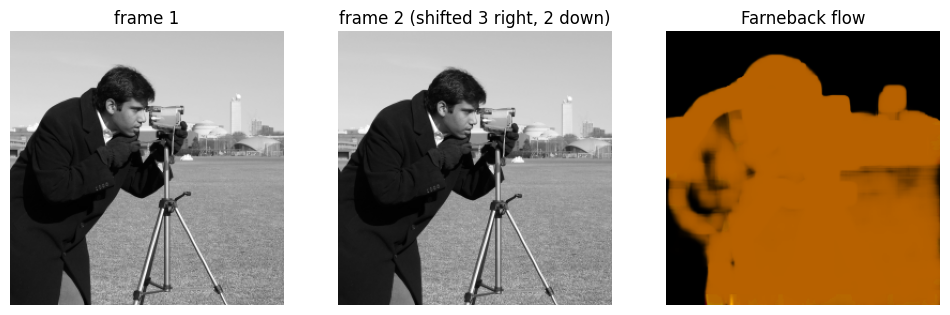

In [3]:
import cv2, numpy as np
import matplotlib.pyplot as plt
from skimage import data

# 1. Two frames: frame 2 = frame 1 shifted 3 pixels right, 2 pixels down
f1 = cv2.resize(data.camera(), (256, 256))          # grayscale test image
M = np.float32([[1, 0, 3], [0, 1, 2]])
f2 = cv2.warpAffine(f1, M, (256, 256), borderMode=cv2.BORDER_REFLECT)

# 2. Farneback dense flow
flow = cv2.calcOpticalFlowFarneback(f1, f2, None,
        pyr_scale=0.5, levels=3, winsize=15,
        iterations=3, poly_n=5, poly_sigma=1.2, flags=0)

# 3. Look at the numbers
print("flow shape:", flow.shape)                  # (256, 256, 2) -> u, v per pixel
print("pixel (128,128): u = %.2f, v = %.2f" % tuple(flow[128, 128]))
print("average:          u = %.2f, v = %.2f" % (flow[..., 0].mean(), flow[..., 1].mean()))

# 4. Show it as color (color = direction, brightness = speed)
mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
hsv = np.zeros((256, 256, 3), np.uint8)
hsv[..., 0] = ang * 180 / np.pi / 2
hsv[..., 1] = 255
hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, t in zip(ax, [f1, f2, rgb], ["frame 1", "frame 2 (shifted 3 right, 2 down)", "Farneback flow"]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.show()